# Estimación de Edad con Redes Neuronales Convolucionales (Regresión)
Este notebook soluciona el problema de calcular la edad exacta de una persona basándose en una imagen de su rostro usando el dataset UTKFace en Google Colab.

In [ ]:
import os
from google.colab import drive

In [ ]:
# Montar Google Drive
drive.mount('/content/drive')

# Configurar la ruta de Kaggle
kaggle_folder_path = "/content/drive/MyDrive/Kaggle"
os.environ['KAGGLE_CONFIG_DIR'] = kaggle_folder_path

# Descarga y extracción del Dataset
if not os.path.exists("utkface-cropped.zip"):
    print("Descargando dataset desde Kaggle...")
    !kaggle datasets download -d moritzm00/utkface-cropped

if not os.path.exists("utkface_aligned_cropped") and not os.path.exists("UTKFace"):
    print("Descomprimiendo...")
    !unzip -q utkface-cropped.zip
    print("Descompresión completada.")

print("\nCarpetas listas")

Mounted at /content/drive
Descargando dataset desde Kaggle...
Dataset URL: https://www.kaggle.com/datasets/moritzm00/utkface-cropped
License(s): unknown
100% 116M/116M [00:09<00:00, 12.9MB/s]

Descomprimiendo...
Descompresión completada.

Carpetas listas


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Procesando archivos...
Total imágenes válidas: 23708


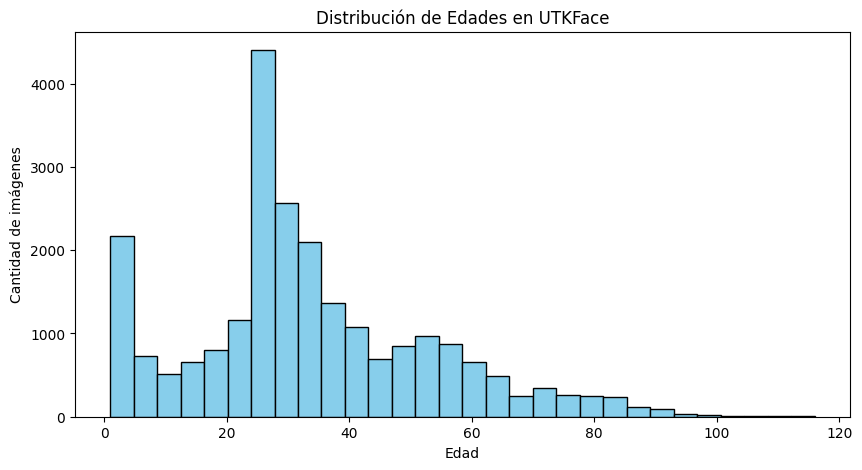

,filepath,age
0,/content/UTKFace/24_0_2_20170116165054448.jpg....,24
1,/content/UTKFace/40_1_3_20170117133747258.jpg....,40
2,/content/UTKFace/38_1_1_20170113183305653.jpg....,38
3,/content/UTKFace/58_1_0_20170109015200826.jpg....,58
4,/content/UTKFace/48_0_0_20170117160506440.jpg....,48


In [ ]:
dataset_path = "/content/UTKFace"

file_paths = []
ages = []

# Procesar imágenes y extraer la edad exacta del nombre del archivo
if os.path.exists(dataset_path):
    print("Procesando archivos...")
    for file in os.listdir(dataset_path):
        if file.endswith(".jpg"):
            parts = file.split("_")
            if len(parts) >= 1 and parts[0].isdigit():
                age = int(parts[0])
                # En teoría el dataset tiene edades hasta 116 (validación x si acaso)
                if age <= 116:
                    file_paths.append(os.path.join(dataset_path, file))
                    ages.append(age)

    print(f"Total imágenes válidas: {len(file_paths)}")

df = pd.DataFrame({'filepath': file_paths, 'age': ages})

# Ver la distribución de las edades
plt.figure(figsize=(10, 5))
plt.hist(df['age'], bins=30, color='skyblue', edgecolor='black')
plt.title("Distribución de Edades en UTKFace")
plt.xlabel("Edad")
plt.ylabel("Cantidad de imágenes")
plt.show()

display(df.head())

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# Separación de datos: 80% Entrenamiento, 10% Validación, 10% Test
# Hacemos split estratificado por rangos de edad para estabilizar el RMSE global.
NUM_AGE_BINS = 12
age_bins = np.linspace(df['age'].min(), df['age'].max() + 1, NUM_AGE_BINS + 1)
df['age_bin'] = pd.cut(df['age'], bins=age_bins, labels=False, include_lowest=True)

df_temp, df_test = train_test_split(
    df,
    test_size=0.1,
    random_state=5,
    stratify=df['age_bin']
)

df_train, df_val = train_test_split(
    df_temp,
    test_size=0.11,
    random_state=5,
    stratify=df_temp['age_bin']
)

# Ya no necesitamos la columna auxiliar para el pipeline.
df_train = df_train.drop(columns=['age_bin'])
df_val = df_val.drop(columns=['age_bin'])
df_test = df_test.drop(columns=['age_bin'])

print(f"Imágenes para entrenamiento: {len(df_train)}")
print(f"Imágenes para validación: {len(df_val)}")
print(f"Imágenes para test: {len(df_test)}")

Imágenes para entrenamiento: 18989
Imágenes para validación: 2348
Imágenes para test: 2371


## Pipeline de Datos Optimizado

In [ ]:
import tensorflow as tf

SEED = 5
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow: {tf.__version__}")

In [ ]:
IMG_SIZE = (96, 96)
BATCH_SIZE = 16

def procesar_imagen(filepath, label):
    # Pipeline simple y rápido para CPU.
    raw_image = tf.io.read_file(filepath)
    image = tf.image.decode_jpeg(raw_image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def create_dataset(df_subset, shuffle=False):
    paths = df_subset['filepath'].values
    labels = df_subset['age'].values.astype(np.float32)

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(procesar_imagen, num_parallel_calls=tf.data.AUTOTUNE)

    if shuffle:
        dataset = dataset.shuffle(buffer_size=min(len(df_subset), 3000), seed=SEED)

    dataset = dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return dataset

ds_train = create_dataset(df_train, shuffle=True)
ds_val = create_dataset(df_val)
ds_test = create_dataset(df_test)

print(f"IMG_SIZE: {IMG_SIZE} | BATCH_SIZE: {BATCH_SIZE}")

## Definición del Modelo (Regresión)

In [ ]:
from tensorflow.keras import layers, models, optimizers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

In [ ]:
def crear_modelo_regresion():
    model = models.Sequential([
        layers.InputLayer(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),

        # Bloque 1
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Bloque 2
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Bloque 3
        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),

        # Cabeza de regresión
        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
        layers.Dropout(0.3),
        layers.Dense(1, activation='linear')
    ])

    model.compile(
        optimizer=optimizers.Adam(learning_rate=8e-4),
        loss=tf.keras.losses.Huber(delta=5.0),
        metrics=[
            tf.keras.metrics.MeanAbsoluteError(name='mae'),
            tf.keras.metrics.RootMeanSquaredError(name='rmse')
        ]
    )

    return model

modelo_regresion = crear_modelo_regresion()
modelo_regresion.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 198, 198, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 198, 198, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 66, 66, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 66, 66, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 30, 30, 128)    │        36,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 30, 30, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 15, 15, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 15, 15, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     3,686,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,729,953 (14.23 MB)

 Trainable params: 3,729,345 (14.23 MB)

 Non-trainable params: 608 (2.38 KB)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_rmse',
    patience=4,
    restore_best_weights=True,
    mode='min',
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_rmse',
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    mode='min',
    verbose=1
)

EPOCHS = 20
print("Entrenando modelo CNN desde cero (CPU friendly)...")
historial = modelo_regresion.fit(
    ds_train,
    validation_data=ds_val,
    epochs=EPOCHS,
    callbacks=[early_stop, reduce_lr],
    verbose=2
)

# Guardar una sola vez al final (evita sobrecosto de I/O por época).
final_model_path = "/content/drive/MyDrive/modelo_regresion_desde_cero_rmse.keras"
modelo_regresion.save(final_model_path)
print(f"\nModelo final guardado en: {final_model_path}")

# Mantenemos el historial en un diccionario para la celda de evaluación.
historial_regresion = historial.history

Comenzando el entrenamiento del modelo de regresión...
Epoch 1/30
594/594 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 1168.5187 - mae: 30.8326 - rmse: 34.1220
Epoch 1: val_rmse improved from None to 15.91581, saving model to /content/drive/MyDrive/modelo_regresion_edad.keras

Epoch 1: finished saving model to /content/drive/MyDrive/modelo_regresion_edad.keras
594/594 ━━━━━━━━━━━━━━━━━━━━ 28s 35ms/step - loss: 917.5387 - mae: 26.9315 - rmse: 30.2909 - val_loss: 253.3130 - val_mae: 11.8434 - val_rmse: 15.9158
Epoch 2/30
593/594 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 242.6905 - mae: 12.3171 - rmse: 15.4618
Epoch 2: val_rmse improved from 15.91581 to 15.86769, saving model to /content/drive/MyDrive/modelo_regresion_edad.keras

Epoch 2: finished saving model to /content/drive/MyDrive/modelo_regresion_edad.keras
594/594 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - loss: 176.5825 - mae: 10.1775 - rmse: 13.2884 - val_loss: 251.7835 - val_mae: 9.1716 - val_rmse: 15.8677
Epoch 3/30
593/594 ━━━━━━━━━━━━

## Evaluación de Resultados

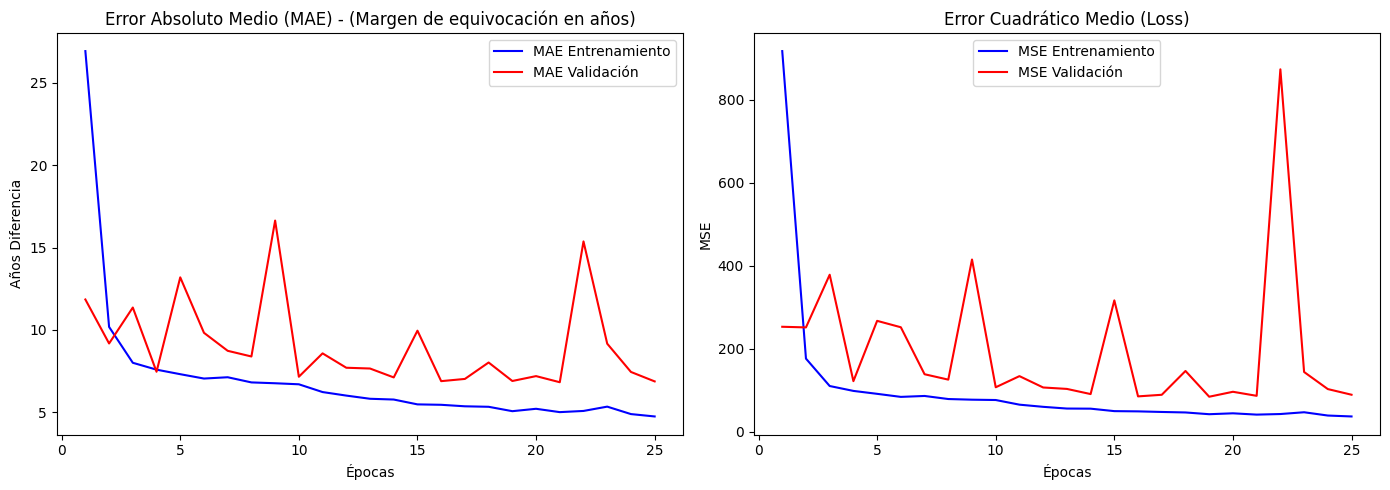


Evaluando con el conjunto de pruebas...
Test Loss (MSE): 89.3979
Test MAE: 6.94 años
Test RMSE: 9.46

En promedio, el modelo se equivoca por: 6.94 años.


In [ ]:
# Graficar métricas de entrenamiento
mae = historial_regresion['mae']
val_mae = historial_regresion['val_mae']
rmse = historial_regresion['rmse']
val_rmse = historial_regresion['val_rmse']
loss = historial_regresion['loss']
val_loss = historial_regresion['val_loss']

epocas = range(1, len(mae) + 1)
best_epoch = int(np.argmin(val_rmse) + 1)
best_val_rmse = float(np.min(val_rmse))

plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
plt.plot(epocas, mae, 'b-', label='MAE Entrenamiento')
plt.plot(epocas, val_mae, 'r-', label='MAE Validación')
plt.title('MAE por época')
plt.xlabel('Épocas')
plt.ylabel('MAE (años)')
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(epocas, rmse, 'b-', label='RMSE Entrenamiento')
plt.plot(epocas, val_rmse, 'r-', label='RMSE Validación')
plt.axvline(best_epoch, color='gray', linestyle='--', alpha=0.6, label=f'Mejor época: {best_epoch}')
plt.title('RMSE por época (objetivo principal)')
plt.xlabel('Épocas')
plt.ylabel('RMSE (años)')
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(epocas, loss, 'b-', label='Huber Entrenamiento')
plt.plot(epocas, val_loss, 'r-', label='Huber Validación')
plt.title('Loss Huber por época')
plt.xlabel('Épocas')
plt.ylabel('Huber Loss')
plt.legend()

plt.tight_layout()
plt.show()

print(f"Mejor RMSE de validación: {best_val_rmse:.3f} (época {best_epoch})")

print("\nEvaluando con el conjunto de pruebas...")
# evaluate devuelve: [loss, mae, rmse]
resultados_test = modelo_regresion.evaluate(ds_test, verbose=0)

print(f"Test Loss (Huber): {resultados_test[0]:.4f}")
print(f"Test MAE: {resultados_test[1]:.2f} años")
print(f"Test RMSE: {resultados_test[2]:.2f} años")

print(f"\nEn promedio, el modelo se equivoca por: {resultados_test[1]:.2f} años.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step


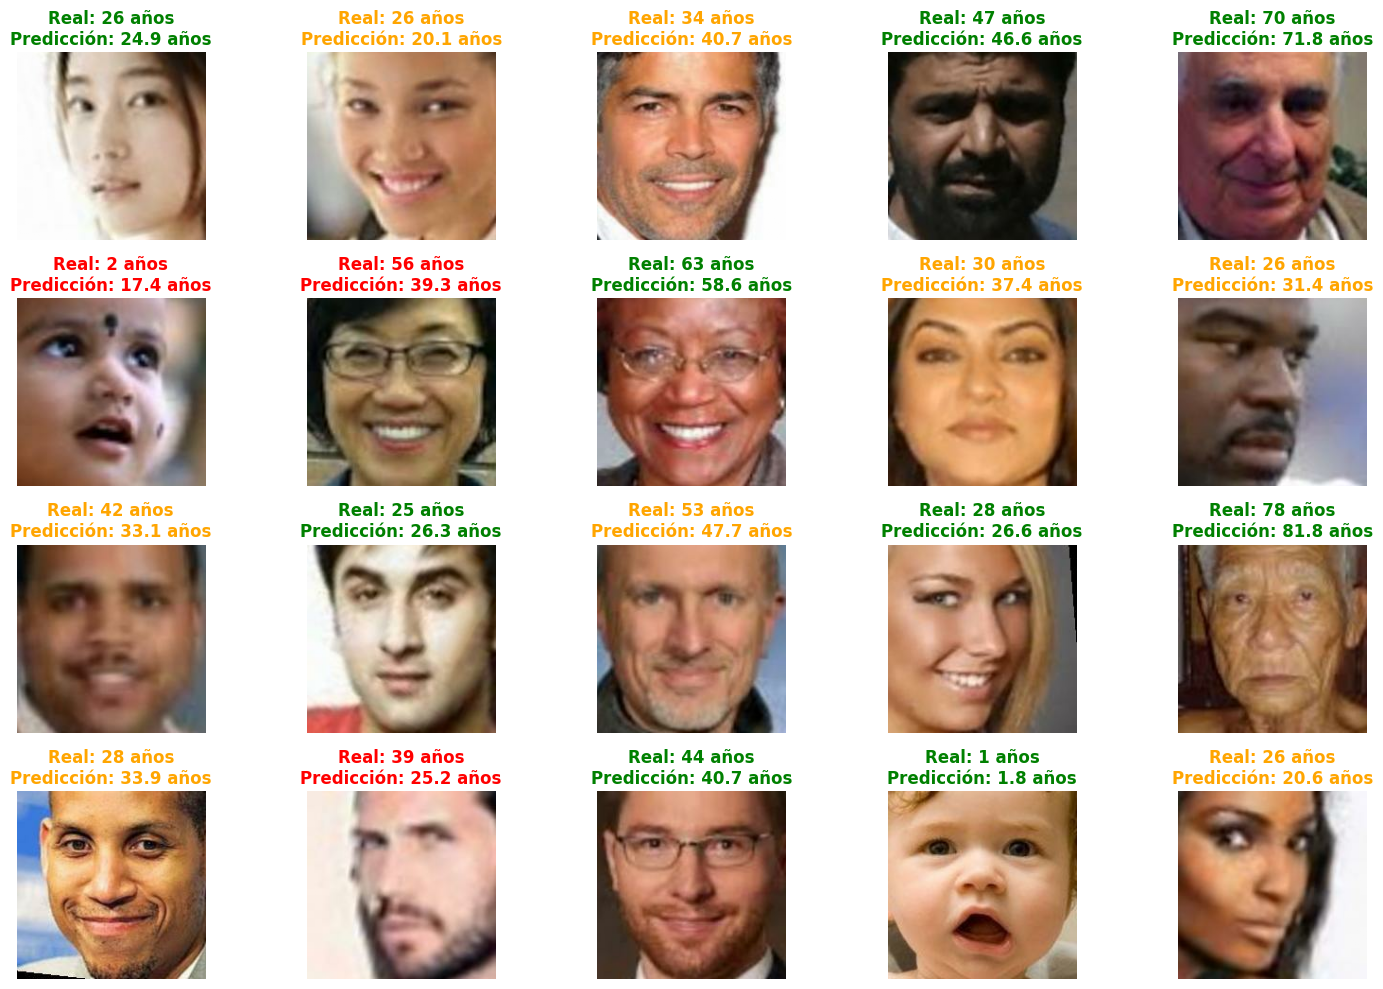

In [ ]:
# Ver predicciones visualmente
for imagenes, edades_reales in ds_test.take(1):
    predicciones = modelo_regresion.predict(imagenes).flatten()

    plt.figure(figsize=(15, 10))
    for i in range(20):
        ax = plt.subplot(4, 5, i + 1)
        plt.imshow(imagenes[i].numpy())

        real = edades_reales[i].numpy()
        pred = predicciones[i]

        # Color verde si el error es menor a 5 años
        color = 'green' if abs(real - pred) <= 5 else 'orange' if abs(real - pred) <= 10 else 'red'

        plt.title(f"Real: {int(real)} años\nPredicción: {pred:.1f} años", color=color, fontweight='bold')
        plt.axis("off")

    plt.tight_layout()
    plt.show()
    break